In [1]:
import xgboost as xgb
import pandas as pd
import seaborn as sns
import logging
import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import shap

from functools import partial
from dataclasses import dataclass
from typing import Dict, List, Tuple

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.model_selection import TimeSeriesSplit, train_test_split
from sklearn.svm import SVR
from sklearn.cluster import KMeans

from config.settings import ROOT_DIR

# ── Пути к файлам ────────────────────────────────────────────────────────────
DATA_RAW_DIR  = ROOT_DIR / "data" / "raw"
DATA_PROC_DIR = ROOT_DIR / "data" / "processed"
OUTPUT_DIR    = ROOT_DIR / "output"

SBERBANK_CSV              = DATA_RAW_DIR / "sberbank_stock_prices.csv"
GOLD_TIME_SERIES_CSV      = DATA_RAW_DIR / "gold_time_series.csv"
OIL_BRENT_TIME_SERIES_CSV = DATA_RAW_DIR / "oil_brent_time_series.csv"
USD_RUB_TIME_SERIES_CSV   = DATA_RAW_DIR / "usd_rub_time_series.csv"
CB_RATE_CSV               = DATA_RAW_DIR / "cb_rate.csv"

# ── Гиперпараметры разбивки данных ───────────────────────────────────────────
TEST_SIZE = 0.2  # Доля тестовой выборки
N_SPLITS  = 3    # Количество фолдов для TimeSeriesSplit

# ── Гиперпараметры Optuna ─────────────────────────────────────────────────────
OPTUNA_SEED  = 42
SVR_N_TRIALS = 100
RF_N_TRIALS  = 100
XGB_N_TRIALS = 100

# ── Гиперпараметры SHAP ───────────────────────────────────────────────────────
# Размер фонового датасета для KernelExplainer (train / test)
SHAP_TRAIN_BACKGROUND_SIZE = 130
SHAP_TEST_BACKGROUND_SIZE  = 100

# Порог для кумулятивного отбора признаков
CUMULATIVE_IMPORTANCE_THRESHOLD = 0.90

WATERFALL_MAX_DISPLAY = 15   # Максимум признаков на Waterfall Plot
SHAP_PLOT_FIGSIZE     = (10, 7)

# ── Настройка логирования и библиотек ────────────────────────────────────────
optuna.logging.set_verbosity(optuna.logging.WARNING)
shap.plots.initjs()

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s - %(levelname)s - %(message)s",
    handlers=[logging.StreamHandler()],
)
logger = logging.getLogger(__name__)

In [2]:
@dataclass
class TrainTestData:
    """Контейнер для хранения обучающей и тестовой выборок."""

    X_train: np.ndarray
    y_train: np.ndarray
    X_test:  np.ndarray
    y_test:  np.ndarray

In [3]:
def test_plot(y_pred: np.ndarray, y_test: pd.Series) -> None:
    """
    Строит линейный график сравнения фактических и предсказанных значений.

    Parameters
    ----------
    y_pred : np.ndarray
        Предсказанные моделью значения.
    y_test : pd.Series
        Фактические значения с индексом-датой.
    """
    plot_df = pd.DataFrame({
        "Date":       y_test.index,
        "True_close": y_test.values,
        "Pred_close": y_pred,
    })

    plt.figure(figsize=(12, 6))
    sns.lineplot(
        data=plot_df, x="Date", y="True_close",
        color="blue", label="Фактические значения (y_test)", linewidth=2,
    )
    sns.lineplot(
        data=plot_df, x="Date", y="Pred_close",
        color="red", marker="o", label="Предсказанные значения (y_pred)",
        linewidth=2,
    )
    plt.title(
        "Сравнение фактических и предсказанных значений",
        fontsize=14, fontweight="bold",
    )
    plt.xlabel("Дата", fontsize=12)
    plt.ylabel("Значения", fontsize=12)
    plt.legend(fontsize=10)
    plt.xticks(rotation=45)
    plt.gcf().autofmt_xdate()
    plt.tight_layout()
    plt.show()


In [4]:
def create_tpe_study() -> optuna.Study:
    """
    Создаёт Optuna-исследование с TPE-сэмплером и Hyperband-прунером.

    Returns
    -------
    optuna.Study
        Исследование, настроенное на минимизацию целевой метрики.
    """
    return optuna.create_study(
        direction="minimize",
        sampler=optuna.samplers.TPESampler(seed=OPTUNA_SEED),
        pruner=optuna.pruners.HyperbandPruner(),
    )

In [5]:
def fit_best_model(model, X_train, y_train, X_test, y_test):
    """
    Обучает готовую модель с учётом специфики XGBoost (eval_set).

    Parameters
    ----------
    model            : sklearn-совместимая модель или XGBRegressor.
    X_train, y_train : обучающая выборка.
    X_test, y_test   : тестовая выборка (используется только для XGBoost).

    Returns
    -------
    Обученная модель.
    """
    if isinstance(model, xgb.XGBRegressor):
        X_tr, X_val, y_tr, y_val = train_test_split(
            X_train, y_train, test_size=0.1, shuffle=False
        )
        model.fit(
            X_tr, y_tr,
            eval_set=[(X_val, y_val)],
            verbose=False,
        )
    else:
        model.fit(X_train, y_train)
    return model

In [6]:
def evaluate_model(
    model, X_test: np.ndarray, y_test: np.ndarray
) -> np.ndarray:
    """
    Вычисляет предсказания и выводит MAPE на тестовой выборке.

    Parameters
    ----------
    model  : обученная модель.
    X_test : признаки тестовой выборки.
    y_test : истинные значения тестовой выборки.

    Returns
    -------
    np.ndarray
        Массив предсказанных значений.
    """
    y_pred = model.predict(X_test)
    mape   = mean_absolute_percentage_error(y_pred, y_test)
    print(f"MAPE: {mape:.6f}")
    return y_pred

In [32]:
def plot_shap_summary(
    shap_values: np.ndarray,
    data: np.ndarray,
    feature_names: List[str],
    model_name: str,
    plot_type: str = "dot",
) -> None:
    """
    Строит SHAP Summary Plot (bee-swarm или bar) для указанной модели.

    Parameters
    ----------
    shap_values   : массив SHAP-значений формы (n_samples, n_features).
    data          : матрица признаков, соответствующая shap_values.
    feature_names : названия признаков.
    model_name    : название модели для заголовка графика.
    plot_type     : 'dot' — bee-swarm plot, 'bar' — столбчатая диаграмма.
    """
    is_dot   = plot_type == "dot"
    prefix   = "SHAP Summary Plot" if is_dot else "Mean |SHAP|"
    subtitle = "Значимость признаков и направление" if is_dot else "Глобальная значимость признаков"

    plt.figure(figsize=SHAP_PLOT_FIGSIZE)
    shap.summary_plot(
        shap_values,
        data,
        feature_names=feature_names,
        plot_type=plot_type,
        show=False,
    )
    plt.title(
        f"{prefix}: {model_name} — {subtitle}",
        fontsize=13, pad=15,
    )
    plt.tight_layout()
    plt.show()

In [8]:
def plot_shap_waterfall(
    explainer,
    X_test: np.ndarray,
    shap_values: np.ndarray,
    y_true: pd.Series,
    model_name: str,
) -> None:
    """
    Строит Waterfall Plot для наблюдения с наибольшим суммарным
    абсолютным SHAP-значением (наиболее "интересный" пример).

    Parameters
    ----------
    explainer   : обученный SHAP-объяснитель.
    X_test      : матрица признаков тестовой выборки.
    shap_values : массив SHAP-значений формы (n_samples, n_features).
    y_true      : серия истинных значений целевой переменной (с индексом).
    model_name  : название модели для заголовка графика.
    """
    most_interesting_idx = np.argmax(np.abs(shap_values).sum(axis=1))
    true_value = y_true.iloc[most_interesting_idx]

    explanation = explainer(X_test)
    plt.figure(figsize=(10, 6))
    shap.plots.waterfall(
        explanation[most_interesting_idx],
        max_display=WATERFALL_MAX_DISPLAY,
        show=False,
    )
    plt.title(
        f"Waterfall Plot ({model_name}): наблюдение #{most_interesting_idx}, "
        f"истинное значение = {true_value:.4f}",
        fontsize=11,
    )
    plt.tight_layout()
    plt.show()

In [9]:
def build_feature_importance_df(
    shap_values: np.ndarray, feature_names: List[str]
) -> pd.DataFrame:
    """
    Формирует DataFrame с глобальной важностью признаков по SHAP.

    Parameters
    ----------
    shap_values   : массив SHAP-значений формы (n_samples, n_features).
    feature_names : названия признаков.

    Returns
    -------
    pd.DataFrame
        Таблица с колонками ['feature', 'mean_abs_shap'],
        отсортированная по убыванию важности.
    """
    mean_abs_shap = np.abs(shap_values).mean(axis=0)
    return (
        pd.DataFrame({
            "feature":       feature_names,
            "mean_abs_shap": mean_abs_shap,
        })
        .sort_values("mean_abs_shap", ascending=False)
        .reset_index(drop=True)
    )

In [10]:
def select_features_by_cumulative_shap(
    importance_df: pd.DataFrame,
    threshold: float = CUMULATIVE_IMPORTANCE_THRESHOLD,
) -> Tuple[List[str], List[str]]:
    """
    Разбивает признаки на «значимые» и «незначимые» по кумулятивной
    SHAP-важности.

    Отбирает минимальный набор признаков, покрывающий заданную долю
    суммарной SHAP-важности (кумулятивный метод). Остальные признаки
    считаются незначимыми и возвращаются отдельным списком.

    Parameters
    ----------
    importance_df : DataFrame из build_feature_importance_df.
    threshold     : доля суммарной важности (по умолчанию
                    CUMULATIVE_IMPORTANCE_THRESHOLD).

    Returns
    -------
    Tuple[List[str], List[str]]
        (selected_features, deleted_features) — признаки в порядке
        убывания важности.
    """
    total_importance = importance_df["mean_abs_shap"].sum()
    cumulative, selected = 0.0, []

    for _, row in importance_df.iterrows():
        cumulative += row["mean_abs_shap"]
        selected.append(row["feature"])
        if cumulative / total_importance >= threshold:
            break

    deleted = [
        f for f in importance_df["feature"] if f not in selected
    ]
    return selected, deleted


def make_feature_split(
    shap_values: np.ndarray,
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_test: pd.DataFrame,
    y_test: pd.Series,
    feature_names: List[str],
) -> Tuple["TrainTestData", "TrainTestData", List[str], List[str]]:
    """
    Строит таблицу важности признаков, отбирает «значимые» и «незначимые»
    и упаковывает их в два объекта TrainTestData.

    Parameters
    ----------
    shap_values   : массив SHAP-значений формы (n_samples, n_features).
    X_train, y_train : полная обучающая выборка.
    X_test, y_test   : полная тестовая выборка.
    feature_names    : список названий признаков.

    Returns
    -------
    Tuple[TrainTestData, TrainTestData, List[str], List[str]]
        (selected_data, deleted_data, selected_features, deleted_features)
    """
    importance_df = build_feature_importance_df(shap_values, feature_names)
    selected, deleted = select_features_by_cumulative_shap(importance_df)

    selected_data = TrainTestData(
        X_train=X_train[selected], y_train=y_train,
        X_test=X_test[selected],   y_test=y_test,
    )
    deleted_data = TrainTestData(
        X_train=X_train[deleted], y_train=y_train,
        X_test=X_test[deleted],   y_test=y_test,
    )
    return selected_data, deleted_data, selected, deleted

In [11]:
df_features = pd.read_parquet(DATA_PROC_DIR / "stable_features.parquet")

In [12]:
df_features.head()

,High_lag_1,Close_lag_1,Low_lag_1,MACD,USDRUB_EMA_13,OIL_ROC_11,OIL_SMA_14,GOLD_intraday_return,MACD_signal,SMA_8,Open_lag_1,USDRUB_SMA_12,GOLD_MACD_signal,GOLD_EMA_SMA_diff,GOLD_lag_6,ROC_8,Close
2020-10-05,211.39,208.80,206.50,-3.535572,77.553295,-5.985157,41.127143,-3.2,1.381731,220.64000,210.40,77.886658,-11.776427,13.510788,1872.8,-8.517350,208.89
2020-10-06,210.69,208.89,207.72,-4.212747,77.626267,-1.549833,41.116429,9.4,0.682421,218.22125,209.60,77.976250,-9.811402,15.016389,1898.7,-8.477918,211.18
2020-10-07,212.99,211.18,208.35,-4.382745,77.731858,1.741412,41.182857,-8.9,0.049275,216.04000,209.00,78.103875,-8.186062,15.156905,1891.3,-7.632419,210.60
2020-10-08,212.66,210.60,209.03,-4.483072,77.764092,0.166985,41.198571,6.9,-0.517268,214.18000,211.31,78.094917,-7.424013,11.164082,1912.3,-6.599255,207.97
2020-10-09,211.43,207.97,207.26,-4.745821,77.686850,3.387405,41.298571,4.2,-1.045837,211.53375,211.21,78.024783,-7.007992,8.373295,1903.8,-9.238893,205.38


In [13]:
X, y = df_features.drop("Close", axis=1), df_features["Close"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, shuffle=False
)

# Глобальный контейнер с данными — используется всеми objective-функциями
train_test_data = TrainTestData(
    X_train=X_train, y_train=y_train,
    X_test=X_test,   y_test=y_test,
)

# Обучение моделей

In [14]:
def model_time_series_validation(
    model, train_test_data: TrainTestData, params: Dict
) -> float:
    """
    Оценивает модель через кросс-валидацию на временном ряде
    (TimeSeriesSplit), затем дообучает на полном train и возвращает
    среднюю ошибку по фолдам.

    Parameters
    ----------
    model           : sklearn-совместимая модель или XGBRegressor.
    train_test_data : контейнер с обучающей и тестовой выборками.
    params          : словарь гиперпараметров (используется для вывода).

    Returns
    -------
    float
        Средний MAPE по валидационным фолдам (train error).
    """
    X_train = train_test_data.X_train
    y_train = train_test_data.y_train
    X_test  = train_test_data.X_test
    y_test  = train_test_data.y_test

    tscv   = TimeSeriesSplit(n_splits=N_SPLITS)
    is_xgb = isinstance(model, xgb.XGBRegressor)

    fold_scores = []
    for train_idx, val_idx in tscv.split(X_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        if is_xgb:
            model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
        else:
            model.fit(X_tr, y_tr)

        fold_scores.append(
            mean_absolute_percentage_error(model.predict(X_val), y_val)
        )

    if is_xgb:
        X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.1, shuffle=False)
        model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
    else:
        model.fit(X_train, y_train)

    train_error = float(np.mean(fold_scores))
    test_error  = mean_absolute_percentage_error(model.predict(X_test), y_test)

    print(f"Train error: {train_error:.6f}; Test error: {test_error:.6f}")
    print(params)

    return train_error

In [ ]:
def svm_objective(trial: optuna.Trial, train_test_data: TrainTestData) -> float:
    params = {
        "C":       trial.suggest_float("C", 1e2, 1e3, log=True),
        "epsilon": trial.suggest_float("epsilon", 1e-3, 10.0, log=True),
        "kernel":  "rbf",
    }
    model = SVR(**params)
    return model_time_series_validation(model, train_test_data, params)

In [46]:
svm_study = create_tpe_study()
svm_study.optimize(
    partial(svm_objective, train_test_data=train_test_data),
    n_trials=SVR_N_TRIALS,
    show_progress_bar=True,
)

  0%|          | 0/100 [00:00<?, ?it/s]

Train error: 0.041654; Test error: 0.056887
{'C': 236.8863950364078, 'epsilon': 6.351221010640703, 'kernel': 'rbf'}
Train error: 0.028280; Test error: 0.027906
{'C': 539.5030966670226, 'epsilon': 0.24810409748678125, 'kernel': 'rbf'}
Train error: 0.035126; Test error: 0.037360
{'C': 143.22493718230254, 'epsilon': 0.004207053950287938, 'kernel': 'rbf'}
Train error: 0.038919; Test error: 0.049737
{'C': 114.30983876313222, 'epsilon': 2.9154431891537547, 'kernel': 'rbf'}
Train error: 0.029345; Test error: 0.033098
{'C': 399.1305878561676, 'epsilon': 0.679657809075816, 'kernel': 'rbf'}
Train error: 0.054262; Test error: 0.057953
{'C': 104.85387725194619, 'epsilon': 7.579479953348009, 'kernel': 'rbf'}
Train error: 0.027870; Test error: 0.021030
{'C': 679.8962421591126, 'epsilon': 0.0070689749506246055, 'kernel': 'rbf'}
Train error: 0.034982; Test error: 0.036815
{'C': 151.9934830130981, 'epsilon': 0.00541524411940254, 'kernel': 'rbf'}
Train error: 0.032834; Test error: 0.035363
{'C': 201.484

In [47]:
svm_model = fit_best_model(
    SVR(**svm_study.best_params),
    X_train, y_train, X_test, y_test,
)

In [ ]:
def rf_objective(trial: optuna.Trial, train_test_data: TrainTestData) -> float:
    params = {
        "n_estimators":          trial.suggest_int("n_estimators", 500, 1500),
        "max_depth":             trial.suggest_int("max_depth", 5, 30),
        "min_samples_split":     trial.suggest_int("min_samples_split", 2, 20),
        "min_samples_leaf":      trial.suggest_int("min_samples_leaf", 1, 10),
        "max_samples":           trial.suggest_float("max_samples", 0.6, 1.0),
        "max_features":          trial.suggest_categorical(
            "max_features", ["sqrt", "log2", 0.3, 0.5, 0.8]
        ),
        "min_impurity_decrease": trial.suggest_float(
            "min_impurity_decrease", 1e-8, 1e-3, log=True
        ),
        "random_state":          trial.suggest_categorical(
            "random_state", [OPTUNA_SEED]
        ),
        "n_jobs": -1,
    }
    model = RandomForestRegressor(**params)
    return model_time_series_validation(model, train_test_data, params)

In [49]:
rf_study = create_tpe_study()
rf_study.optimize(
    partial(rf_objective, train_test_data=train_test_data),
    n_trials=RF_N_TRIALS,
    show_progress_bar=True,
)

  0%|          | 0/100 [00:00<?, ?it/s]

Train error: 0.108986; Test error: 0.011335
{'n_estimators': 874, 'max_depth': 29, 'min_samples_split': 15, 'min_samples_leaf': 6, 'max_samples': 0.6624074561769746, 'max_features': 0.3, 'min_impurity_decrease': 1.2674255898937194e-08, 'random_state': 42, 'n_jobs': -1}
Train error: 0.102768; Test error: 0.010315
{'n_estimators': 1470, 'max_depth': 26, 'min_samples_split': 6, 'min_samples_leaf': 2, 'max_samples': 0.6733618039413735, 'max_features': 0.8, 'min_impurity_decrease': 4.982752357076433e-08, 'random_state': 42, 'n_jobs': -1}
Train error: 0.103222; Test error: 0.010390
{'n_estimators': 792, 'max_depth': 14, 'min_samples_split': 10, 'min_samples_leaf': 8, 'max_samples': 0.6798695128633439, 'max_features': 0.5, 'min_impurity_decrease': 2.1147447960615646e-08, 'random_state': 42, 'n_jobs': -1}
Train error: 0.108812; Test error: 0.011423
{'n_estimators': 1449, 'max_depth': 30, 'min_samples_split': 17, 'min_samples_leaf': 4, 'max_samples': 0.6390688456025535, 'max_features': 'sqrt', 

In [55]:
rf_model = fit_best_model(
    RandomForestRegressor(**rf_study.best_params),
    X_train, y_train, X_test, y_test,
)

In [ ]:
def gb_objective(trial: optuna.Trial, train_test_data: TrainTestData) -> float:

    params = {
        "tree_method": trial.suggest_categorical("tree_method", ["hist"]),
        "n_estimators": trial.suggest_categorical("n_estimators", [2000]),
        "max_depth": trial.suggest_int("max_depth", 2, 2),
        "min_child_weight": trial.suggest_float("min_child_weight", 5.0, 50.0, log=True),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.05, log=True),
        "subsample": trial.suggest_float("subsample", 0.4, 0.6),
        "colsample_bytree": trial.suggest_categorical("colsample_bytree", [0.6, 0.7, 0.8]),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e1, 1e3, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-2, 1e1, log=True),
        "gamma": trial.suggest_float("gamma", 1e-3, 1.0, log=True),
        "early_stopping_rounds": trial.suggest_categorical("early_stopping_rounds", [100]),
        "random_state": trial.suggest_categorical("random_state", [OPTUNA_SEED]),
        "n_jobs": -1,
    }
    model = xgb.XGBRegressor(**params)
    return model_time_series_validation(model, train_test_data, params)

In [50]:
gb_study = create_tpe_study()
gb_study.optimize(
    partial(gb_objective, train_test_data=train_test_data),
    n_trials=XGB_N_TRIALS,
    show_progress_bar=True,
)

  0%|          | 0/100 [00:00<?, ?it/s]

Train error: 0.103753; Test error: 0.010828
{'tree_method': 'hist', 'n_estimators': 2000, 'max_depth': 2, 'min_child_weight': 11.844319751820388, 'learning_rate': 0.044635901521768134, 'subsample': 0.546398788362281, 'colsample_bytree': 0.6, 'reg_lambda': 13.066739238053282, 'reg_alpha': 3.9676050770529883, 'gamma': 0.06358358856676251, 'early_stopping_rounds': 100, 'random_state': 42, 'n_jobs': -1}
Train error: 0.104157; Test error: 0.010530
{'tree_method': 'hist', 'n_estimators': 2000, 'max_depth': 2, 'min_child_weight': 25.52951604697378, 'learning_rate': 0.005242693862597309, 'subsample': 0.5939819704323989, 'colsample_bytree': 0.6, 'reg_lambda': 23.270677083837796, 'reg_alpha': 0.08179499475211674, 'gamma': 0.03752055855124281, 'early_stopping_rounds': 100, 'random_state': 42, 'n_jobs': -1}
Train error: 0.102223; Test error: 0.010490
{'tree_method': 'hist', 'n_estimators': 2000, 'max_depth': 2, 'min_child_weight': 13.518080333310003, 'learning_rate': 0.009776854331372627, 'subsamp

In [48]:
gb_model = fit_best_model(
    xgb.XGBRegressor(**gb_study.best_params),
    X_train, y_train, X_test, y_test,
)

# Сохранение моделей

Сериализация обученных моделей на диск с помощью `joblib`.
Позволяет переиспользовать модели без повторного обучения.

In [60]:
joblib.dump(svm_model, OUTPUT_DIR / "SVM_model.pkl")
joblib.dump(rf_model,  OUTPUT_DIR / "RF_model.pkl")
joblib.dump(gb_model,  OUTPUT_DIR / "GB_model.pkl")

['D:\\ML projects\\Sberbank stock prices prediction\\src\\output\\GB_model.pkl']

# Загрузка моделей

Загрузка ранее сохранённых моделей. Ячейку следует запускать
вместо блока обучения при повторном открытии ноутбука.

In [18]:
svm_model = joblib.load(OUTPUT_DIR / "SVM_model.pkl")
rf_model  = joblib.load(OUTPUT_DIR / "RF_model.pkl")
gb_model  = joblib.load(OUTPUT_DIR / "GB_model.pkl")

# Оценка моделей

In [19]:
svm_y_pred = evaluate_model(svm_model, X_test, y_test)

MAPE: 0.017443


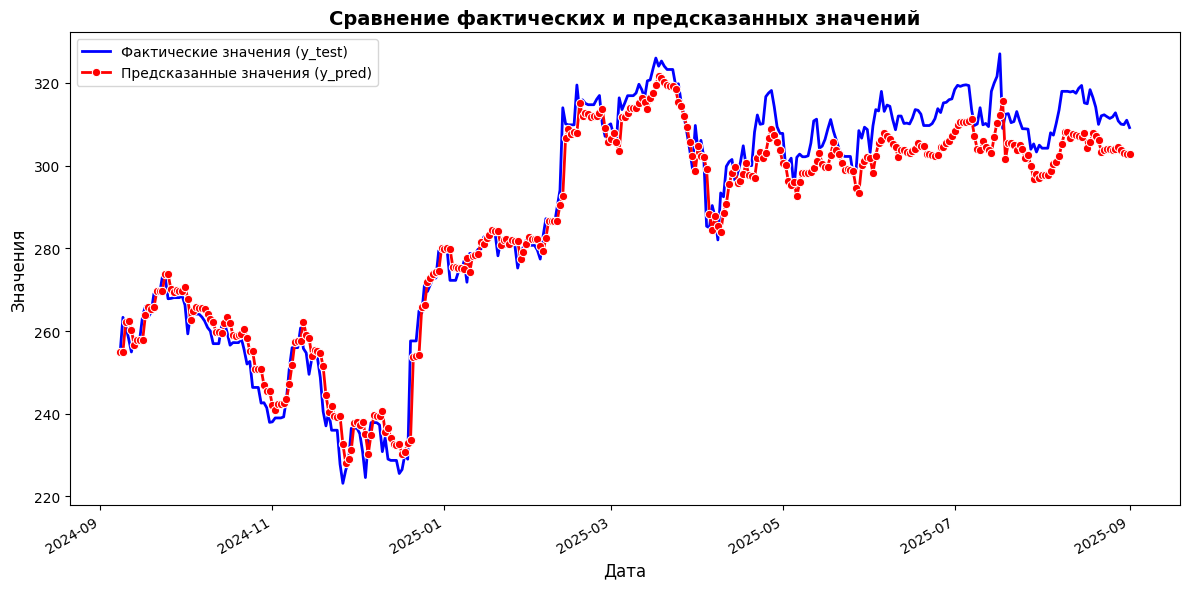

In [20]:
test_plot(svm_y_pred, y_test)

In [21]:
rf_y_pred = evaluate_model(rf_model, X_test, y_test)

MAPE: 0.010349


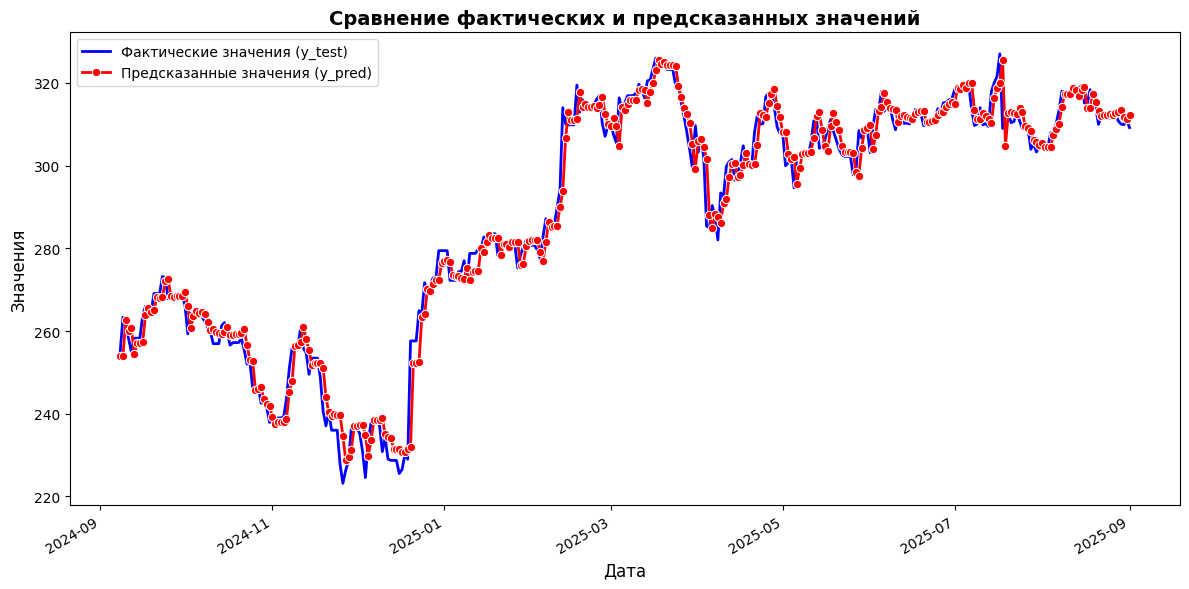

In [22]:
test_plot(rf_y_pred, y_test)

In [23]:
gb_y_pred = evaluate_model(gb_model, X_test, y_test)

MAPE: 0.010271


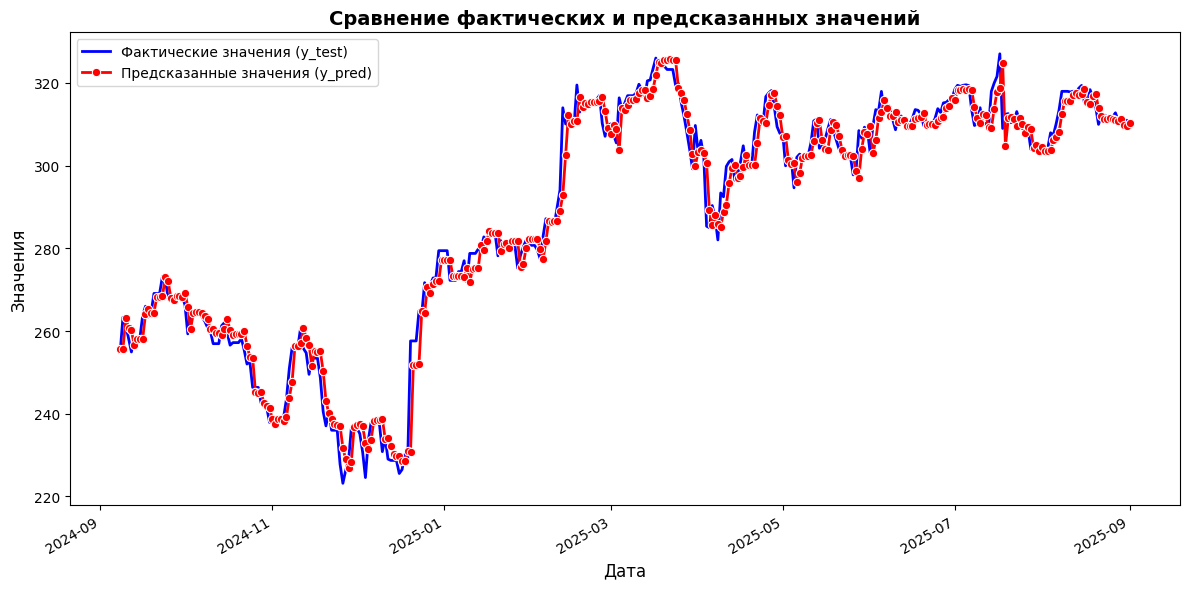

In [24]:
test_plot(gb_y_pred, y_test)

# Создание объяснителей (Explainers)

- **SVR** использует `KernelExplainer` (модель-чёрный ящик).
- **RF** и **XGBoost** используют `TreeExplainer` — точный и быстрый
  алгоритм, использующий структуру деревьев напрямую.

In [25]:
# Фоновые датасеты для KernelExplainer.
# Train-фон задаёт базовое значение объяснителя;
# test-фон — это наблюдения, для которых вычисляются SHAP-значения.
train_background = shap.sample(
    X_train, SHAP_TRAIN_BACKGROUND_SIZE, random_state=OPTUNA_SEED
)
test_background = shap.sample(
    X_test, SHAP_TEST_BACKGROUND_SIZE, random_state=OPTUNA_SEED
)

In [ ]:
# KernelExplainer работает с любой моделью как с чёрным ящиком.
# Вычисление SHAP-значений занимает значительное время.
svm_explainer   = shap.KernelExplainer(
    svm_model.predict, data=train_background
)
svm_shap_values = svm_explainer.shap_values(test_background, silent=False)

In [20]:
# Сохраняем SHAP-значения: вычисление KernelExplainer занимает долго
joblib.dump(svm_shap_values, OUTPUT_DIR / "SVM_shap_values.pkl")

NameError: name 'svm_shap_values' is not defined

In [26]:
# Загружаем предварительно рассчитанные SHAP-значения SVR
svm_shap_values = joblib.load(OUTPUT_DIR / "SVM_shap_values.pkl")

In [27]:
# TreeExplainer вычисляет точные значения Шепли через структуру деревьев
rf_explainer   = shap.TreeExplainer(rf_model)
rf_shap_values = rf_explainer.shap_values(X_test)

In [28]:
gb_explainer   = shap.TreeExplainer(gb_model)
gb_shap_values = gb_explainer.shap_values(X_test)

# Summary Plot

Bee-swarm график: глобальный рейтинг важности признаков и направление
их влияния на прогноз. Цвет точки — значение признака (красный = высокое,
синий = низкое). Позиция по оси X — SHAP-значение.

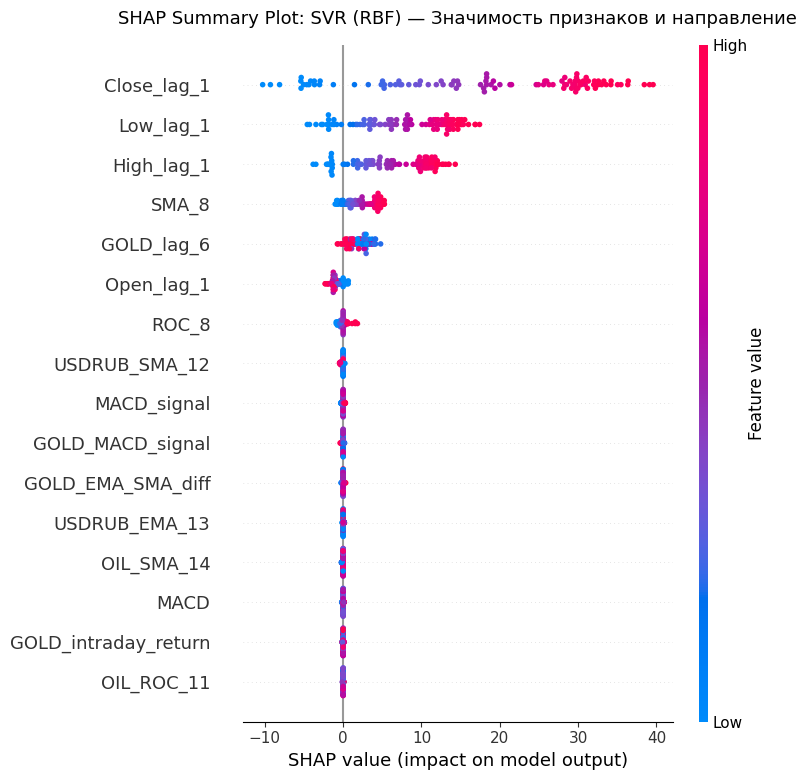

In [33]:
plot_shap_summary(
    svm_shap_values, test_background,
    feature_names=X.columns, model_name="SVR (RBF)",
)

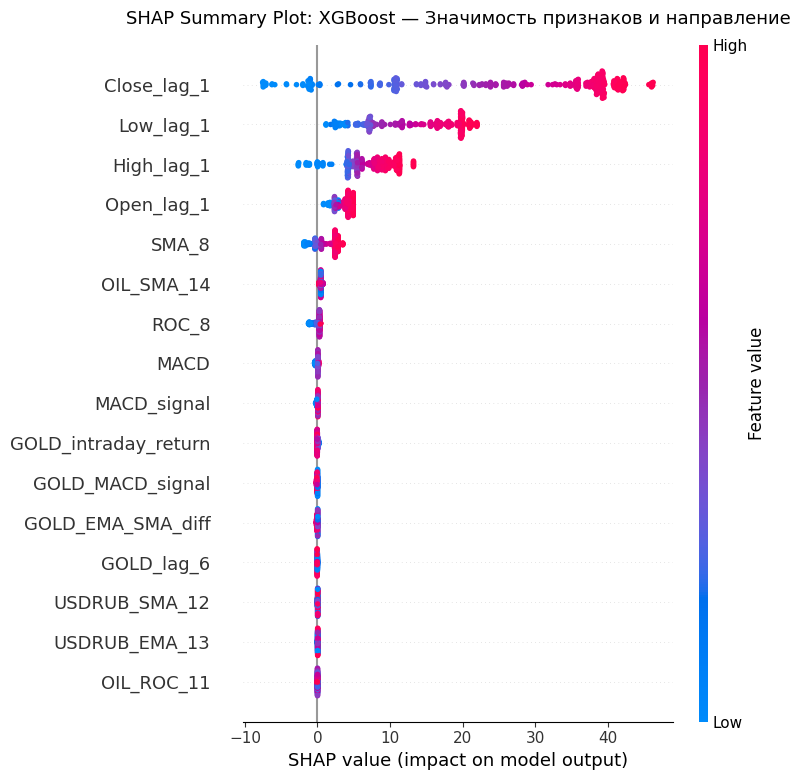

In [34]:
plot_shap_summary(
    gb_shap_values, X_test,
    feature_names=X.columns, model_name="XGBoost",
)

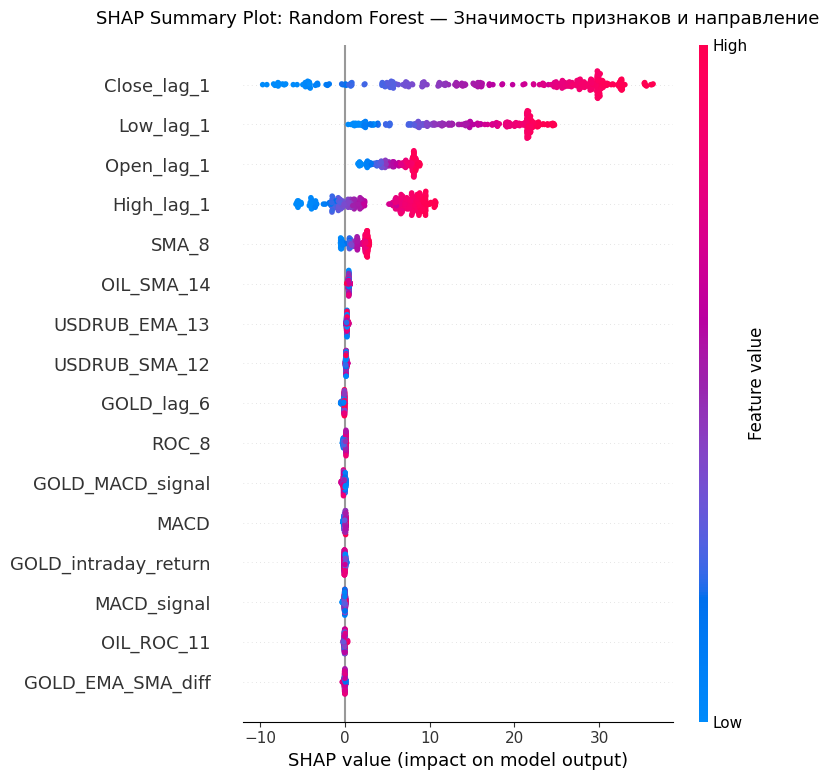

In [35]:
plot_shap_summary(
    rf_shap_values, X_test,
    feature_names=X.columns, model_name="Random Forest",
)

# Bar Plot

Столбчатая диаграмма глобальной важности признаков:
среднее абсолютное SHAP-значение по всей выборке.

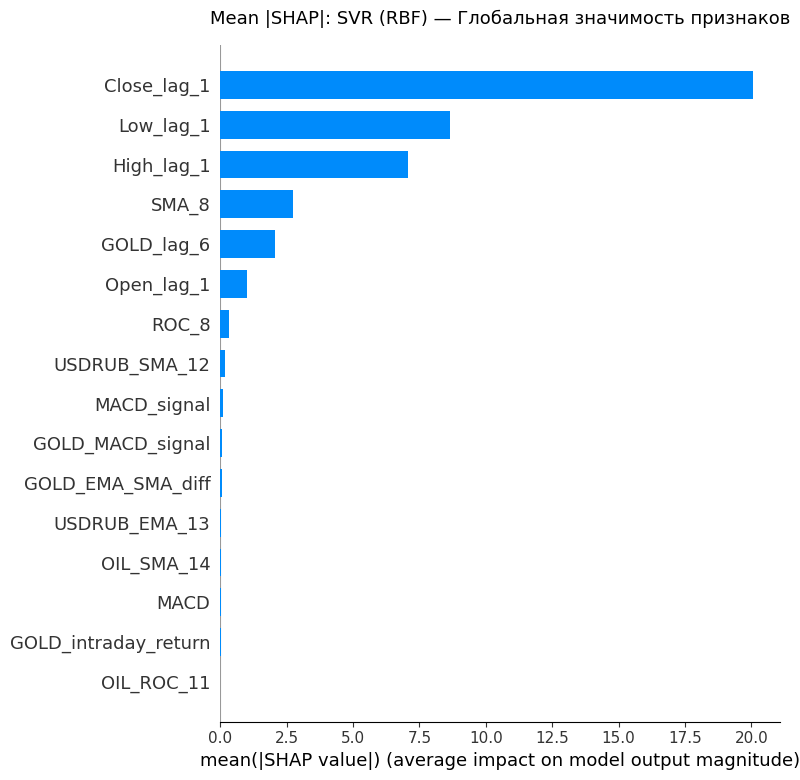

In [36]:
plot_shap_summary(
    svm_shap_values, test_background,
    feature_names=X.columns, model_name="SVR (RBF)", plot_type="bar",
)

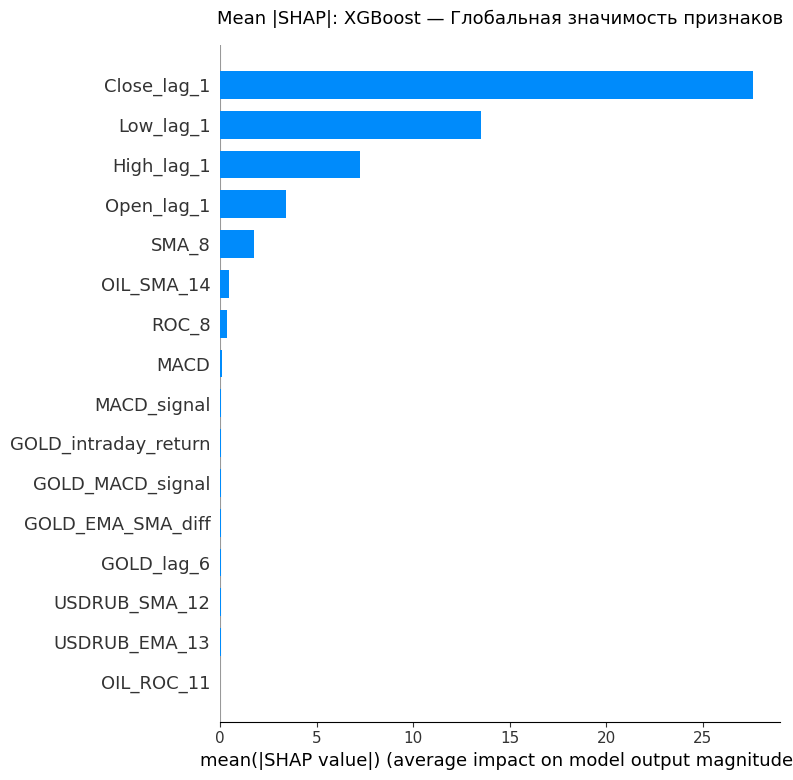

In [37]:
plot_shap_summary(
    gb_shap_values, X_test,
    feature_names=X.columns, model_name="XGBoost", plot_type="bar",
)

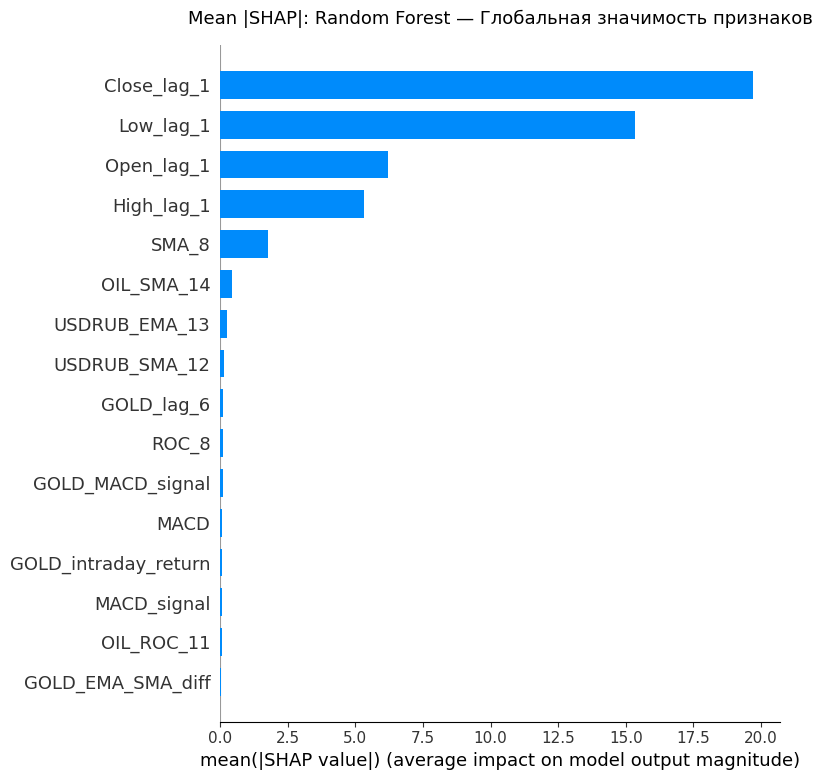

In [38]:
plot_shap_summary(
    rf_shap_values, X_test,
    feature_names=X.columns, model_name="Random Forest", plot_type="bar",
)

# Отбор признаков

Кумулятивный метод: выбирается минимальный набор признаков,
покрывающий `CUMULATIVE_IMPORTANCE_THRESHOLD` суммарной SHAP-важности.
Для каждой модели строятся два варианта данных:
- **selected** — значимые признаки;
- **deleted** — незначимые признаки (контрольная группа).

In [51]:
(
    svm_selected_features_data,
    svm_deleted_features_data,
    svm_selected_features,
    svm_deleted_features,
) = make_feature_split(
    svm_shap_values, X_train, y_train, X_test, y_test,
    feature_names=X.columns.tolist(),
)

In [52]:
svm_study_selected_features = create_tpe_study()
svm_study_selected_features.optimize(
    partial(svm_objective, train_test_data=svm_selected_features_data),
    n_trials=SVR_N_TRIALS,
    show_progress_bar=True,
)

  0%|          | 0/100 [00:00<?, ?it/s]

Train error: 0.123814; Test error: 0.010257
{'C': 236.8863950364078, 'epsilon': 6.351221010640703, 'kernel': 'rbf'}
Train error: 0.118731; Test error: 0.008865
{'C': 539.5030966670226, 'epsilon': 0.24810409748678125, 'kernel': 'rbf'}
Train error: 0.117392; Test error: 0.008772
{'C': 143.22493718230254, 'epsilon': 0.004207053950287938, 'kernel': 'rbf'}
Train error: 0.121409; Test error: 0.009355
{'C': 114.30983876313222, 'epsilon': 2.9154431891537547, 'kernel': 'rbf'}
Train error: 0.119946; Test error: 0.009011
{'C': 399.1305878561676, 'epsilon': 0.679657809075816, 'kernel': 'rbf'}
Train error: 0.124358; Test error: 0.011018
{'C': 104.85387725194619, 'epsilon': 7.579479953348009, 'kernel': 'rbf'}
Train error: 0.119289; Test error: 0.008769
{'C': 679.8962421591126, 'epsilon': 0.0070689749506246055, 'kernel': 'rbf'}
Train error: 0.117400; Test error: 0.008773
{'C': 151.9934830130981, 'epsilon': 0.00541524411940254, 'kernel': 'rbf'}
Train error: 0.117744; Test error: 0.008809
{'C': 201.484

In [53]:
svm_study_deleted_features = create_tpe_study()
svm_study_deleted_features.optimize(
    partial(svm_objective, train_test_data=svm_deleted_features_data),
    n_trials=SVR_N_TRIALS,
    show_progress_bar=True,
)

  0%|          | 0/100 [00:00<?, ?it/s]

Train error: 0.078567; Test error: 0.047619
{'C': 236.8863950364078, 'epsilon': 6.351221010640703, 'kernel': 'rbf'}
Train error: 0.055107; Test error: 0.043088
{'C': 539.5030966670226, 'epsilon': 0.24810409748678125, 'kernel': 'rbf'}
Train error: 0.081310; Test error: 0.037913
{'C': 143.22493718230254, 'epsilon': 0.004207053950287938, 'kernel': 'rbf'}
Train error: 0.094780; Test error: 0.046359
{'C': 114.30983876313222, 'epsilon': 2.9154431891537547, 'kernel': 'rbf'}
Train error: 0.057911; Test error: 0.039576
{'C': 399.1305878561676, 'epsilon': 0.679657809075816, 'kernel': 'rbf'}
Train error: 0.110371; Test error: 0.047645
{'C': 104.85387725194619, 'epsilon': 7.579479953348009, 'kernel': 'rbf'}
Train error: 0.054380; Test error: 0.045899
{'C': 679.8962421591126, 'epsilon': 0.0070689749506246055, 'kernel': 'rbf'}
Train error: 0.079346; Test error: 0.037881
{'C': 151.9934830130981, 'epsilon': 0.00541524411940254, 'kernel': 'rbf'}
Train error: 0.069287; Test error: 0.039064
{'C': 201.484

In [54]:
svm_model_selected_features = fit_best_model(
    SVR(**svm_study_selected_features.best_params),
    svm_selected_features_data.X_train, svm_selected_features_data.y_train,
    svm_selected_features_data.X_test,  svm_selected_features_data.y_test,
)
svm_y_pred_selected_features = evaluate_model(
    svm_model_selected_features,
    svm_selected_features_data.X_test,
    svm_selected_features_data.y_test,
)

MAPE: 0.008775


In [55]:
svm_model_deleted_features = fit_best_model(
    SVR(**svm_study_deleted_features.best_params),
    svm_deleted_features_data.X_train, svm_deleted_features_data.y_train,
    svm_deleted_features_data.X_test,  svm_deleted_features_data.y_test,
)
svm_y_pred_deleted_features = evaluate_model(
    svm_model_deleted_features,
    svm_deleted_features_data.X_test,
    svm_deleted_features_data.y_test,
)

MAPE: 0.051215


In [ ]:
joblib.dump(
    svm_model_selected_features,
    OUTPUT_DIR / "SVM_model_selected_features.pkl",
)
joblib.dump(
    svm_model_deleted_features,
    OUTPUT_DIR / "SVM_model_deleted_features.pkl",
)

In [40]:
svm_model_selected_features = joblib.load(
    OUTPUT_DIR / "SVM_model_selected_features.pkl"
)
svm_model_deleted_features = joblib.load(
    OUTPUT_DIR / "SVM_model_deleted_features.pkl"
)

In [56]:
(
    gb_selected_features_data,
    gb_deleted_features_data,
    gb_selected_features,
    gb_deleted_features,
) = make_feature_split(
    gb_shap_values, X_train, y_train, X_test, y_test,
    feature_names=X.columns.tolist(),
)

In [57]:
gb_study_selected_features = create_tpe_study()
gb_study_selected_features.optimize(
    partial(gb_objective, train_test_data=gb_selected_features_data),
    n_trials=XGB_N_TRIALS,
    show_progress_bar=True,
)

  0%|          | 0/100 [00:00<?, ?it/s]

Train error: 0.092269; Test error: 0.010704
{'tree_method': 'hist', 'n_estimators': 2000, 'max_depth': 2, 'min_child_weight': 11.844319751820388, 'learning_rate': 0.044635901521768134, 'subsample': 0.546398788362281, 'colsample_bytree': 0.6, 'reg_lambda': 13.066739238053282, 'reg_alpha': 3.9676050770529883, 'gamma': 0.06358358856676251, 'early_stopping_rounds': 100, 'random_state': 42, 'n_jobs': -1}
Train error: 0.094213; Test error: 0.010660
{'tree_method': 'hist', 'n_estimators': 2000, 'max_depth': 2, 'min_child_weight': 25.52951604697378, 'learning_rate': 0.005242693862597309, 'subsample': 0.5939819704323989, 'colsample_bytree': 0.6, 'reg_lambda': 23.270677083837796, 'reg_alpha': 0.08179499475211674, 'gamma': 0.03752055855124281, 'early_stopping_rounds': 100, 'random_state': 42, 'n_jobs': -1}
Train error: 0.095657; Test error: 0.010233
{'tree_method': 'hist', 'n_estimators': 2000, 'max_depth': 2, 'min_child_weight': 13.518080333310003, 'learning_rate': 0.009776854331372627, 'subsamp

In [58]:
gb_study_deleted_features = create_tpe_study()
gb_study_deleted_features.optimize(
    partial(gb_objective, train_test_data=gb_deleted_features_data),
    n_trials=XGB_N_TRIALS,
    show_progress_bar=True,
)

  0%|          | 0/100 [00:00<?, ?it/s]

Train error: 0.151989; Test error: 0.018577
{'tree_method': 'hist', 'n_estimators': 2000, 'max_depth': 2, 'min_child_weight': 11.844319751820388, 'learning_rate': 0.044635901521768134, 'subsample': 0.546398788362281, 'colsample_bytree': 0.6, 'reg_lambda': 13.066739238053282, 'reg_alpha': 3.9676050770529883, 'gamma': 0.06358358856676251, 'early_stopping_rounds': 100, 'random_state': 42, 'n_jobs': -1}
Train error: 0.167604; Test error: 0.025070
{'tree_method': 'hist', 'n_estimators': 2000, 'max_depth': 2, 'min_child_weight': 25.52951604697378, 'learning_rate': 0.005242693862597309, 'subsample': 0.5939819704323989, 'colsample_bytree': 0.6, 'reg_lambda': 23.270677083837796, 'reg_alpha': 0.08179499475211674, 'gamma': 0.03752055855124281, 'early_stopping_rounds': 100, 'random_state': 42, 'n_jobs': -1}
Train error: 0.151997; Test error: 0.018985
{'tree_method': 'hist', 'n_estimators': 2000, 'max_depth': 2, 'min_child_weight': 13.518080333310003, 'learning_rate': 0.009776854331372627, 'subsamp

In [ ]:
gb_model_selected_features = fit_best_model(
    xgb.XGBRegressor(**gb_study_selected_features.best_params),
    gb_selected_features_data.X_train, gb_selected_features_data.y_train,
    gb_selected_features_data.X_test,  gb_selected_features_data.y_test,
)
gb_y_pred_selected_features = evaluate_model(
    gb_model_selected_features,
    gb_selected_features_data.X_test,
    gb_selected_features_data.y_test,
)

In [ ]:
gb_model_deleted_features = fit_best_model(
    xgb.XGBRegressor(**gb_study_deleted_features.best_params),
    gb_deleted_features_data.X_train, gb_deleted_features_data.y_train,
    gb_deleted_features_data.X_test,  gb_deleted_features_data.y_test,
)
gb_y_pred_deleted_features = evaluate_model(
    gb_model_deleted_features,
    gb_deleted_features_data.X_test,
    gb_deleted_features_data.y_test,
)

In [ ]:
joblib.dump(
    gb_model_selected_features,
    OUTPUT_DIR / "GB_model_selected_features.pkl",
)
joblib.dump(
    gb_model_deleted_features,
    OUTPUT_DIR / "GB_model_deleted_features.pkl",
)

In [42]:
gb_model_selected_features = joblib.load(
    OUTPUT_DIR / "GB_model_selected_features.pkl"
)
gb_model_deleted_features = joblib.load(
    OUTPUT_DIR / "GB_model_deleted_features.pkl"
)

In [59]:
(
    rf_selected_features_data,
    rf_deleted_features_data,
    rf_selected_features,
    rf_deleted_features,
) = make_feature_split(
    rf_shap_values, X_train, y_train, X_test, y_test,
    feature_names=X.columns.tolist(),
)

In [60]:
rf_study_selected_features = create_tpe_study()
rf_study_selected_features.optimize(
    partial(rf_objective, train_test_data=rf_selected_features_data),
    n_trials=RF_N_TRIALS,
    show_progress_bar=True,
)

  0%|          | 0/100 [00:00<?, ?it/s]

Train error: 0.093426; Test error: 0.010708
{'n_estimators': 874, 'max_depth': 29, 'min_samples_split': 15, 'min_samples_leaf': 6, 'max_samples': 0.6624074561769746, 'max_features': 0.3, 'min_impurity_decrease': 1.2674255898937194e-08, 'random_state': 42, 'n_jobs': -1}
Train error: 0.090438; Test error: 0.010645
{'n_estimators': 1470, 'max_depth': 26, 'min_samples_split': 6, 'min_samples_leaf': 2, 'max_samples': 0.6733618039413735, 'max_features': 0.8, 'min_impurity_decrease': 4.982752357076433e-08, 'random_state': 42, 'n_jobs': -1}
Train error: 0.093103; Test error: 0.010298
{'n_estimators': 792, 'max_depth': 14, 'min_samples_split': 10, 'min_samples_leaf': 8, 'max_samples': 0.6798695128633439, 'max_features': 0.5, 'min_impurity_decrease': 2.1147447960615646e-08, 'random_state': 42, 'n_jobs': -1}
Train error: 0.092800; Test error: 0.010318
{'n_estimators': 1449, 'max_depth': 30, 'min_samples_split': 17, 'min_samples_leaf': 4, 'max_samples': 0.6390688456025535, 'max_features': 'sqrt', 

In [61]:
rf_study_deleted_features = create_tpe_study()
rf_study_deleted_features.optimize(
    partial(rf_objective, train_test_data=rf_deleted_features_data),
    n_trials=RF_N_TRIALS,
    show_progress_bar=True,
)

  0%|          | 0/100 [00:00<?, ?it/s]

Train error: 0.188252; Test error: 0.050387
{'n_estimators': 874, 'max_depth': 29, 'min_samples_split': 15, 'min_samples_leaf': 6, 'max_samples': 0.6624074561769746, 'max_features': 0.3, 'min_impurity_decrease': 1.2674255898937194e-08, 'random_state': 42, 'n_jobs': -1}
Train error: 0.139155; Test error: 0.016099
{'n_estimators': 1470, 'max_depth': 26, 'min_samples_split': 6, 'min_samples_leaf': 2, 'max_samples': 0.6733618039413735, 'max_features': 0.8, 'min_impurity_decrease': 4.982752357076433e-08, 'random_state': 42, 'n_jobs': -1}
Train error: 0.157388; Test error: 0.020461
{'n_estimators': 792, 'max_depth': 14, 'min_samples_split': 10, 'min_samples_leaf': 8, 'max_samples': 0.6798695128633439, 'max_features': 0.5, 'min_impurity_decrease': 2.1147447960615646e-08, 'random_state': 42, 'n_jobs': -1}
Train error: 0.188061; Test error: 0.046880
{'n_estimators': 1449, 'max_depth': 30, 'min_samples_split': 17, 'min_samples_leaf': 4, 'max_samples': 0.6390688456025535, 'max_features': 'sqrt', 

In [ ]:
rf_model_selected_features = fit_best_model(
    RandomForestRegressor(**rf_study_selected_features.best_params),
    rf_selected_features_data.X_train, rf_selected_features_data.y_train,
    rf_selected_features_data.X_test,  rf_selected_features_data.y_test,
)
rf_y_pred_selected_features = evaluate_model(
    rf_model_selected_features,
    rf_selected_features_data.X_test,
    rf_selected_features_data.y_test,
)

In [ ]:
rf_model_deleted_features = fit_best_model(
    RandomForestRegressor(**rf_study_deleted_features.best_params),
    rf_deleted_features_data.X_train, rf_deleted_features_data.y_train,
    rf_deleted_features_data.X_test,  rf_deleted_features_data.y_test,
)
rf_y_pred_deleted_features = evaluate_model(
    rf_model_deleted_features,
    rf_deleted_features_data.X_test,
    rf_deleted_features_data.y_test,
)

In [ ]:
joblib.dump(
    rf_model_selected_features,
    OUTPUT_DIR / "RF_model_selected_features.pkl",
)
joblib.dump(
    rf_model_deleted_features,
    OUTPUT_DIR / "RF_model_deleted_features.pkl",
)

In [44]:
rf_model_selected_features = joblib.load(
    OUTPUT_DIR / "RF_model_selected_features.pkl"
)
rf_model_deleted_features = joblib.load(
    OUTPUT_DIR / "RF_model_deleted_features.pkl"
)

In [45]:
svm_y_pred_selected_features = evaluate_model(svm_model_selected_features, svm_selected_features_data.X_test, y_test)
svm_y_pred_deleted_features = evaluate_model(svm_model_deleted_features, svm_deleted_features_data.X_test, y_test)

MAPE: 0.008775
MAPE: 0.051215


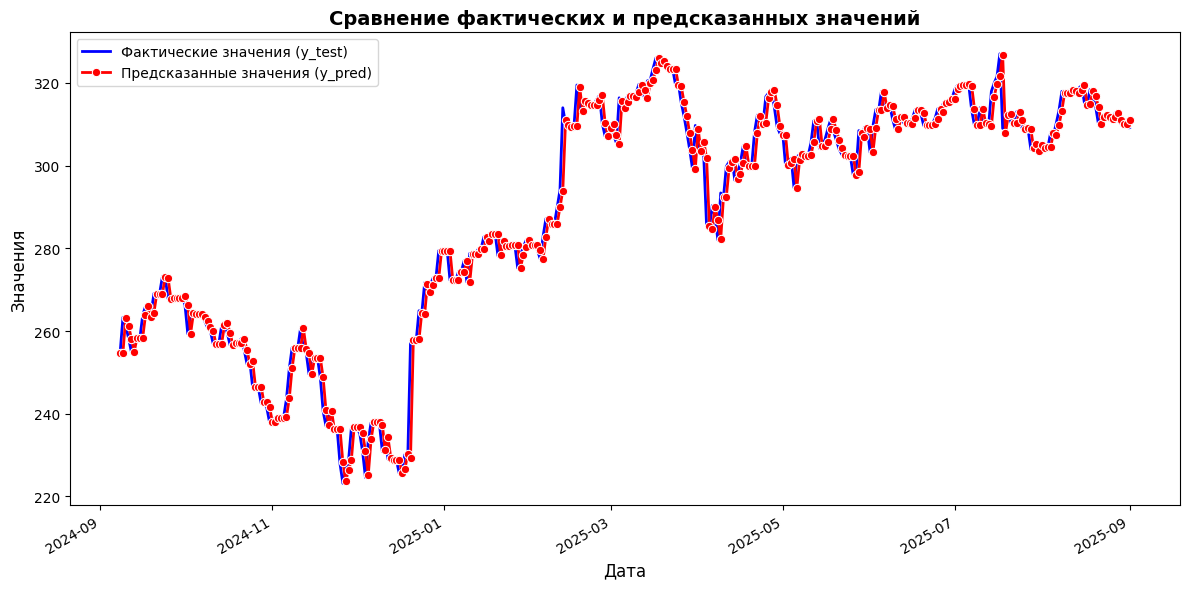

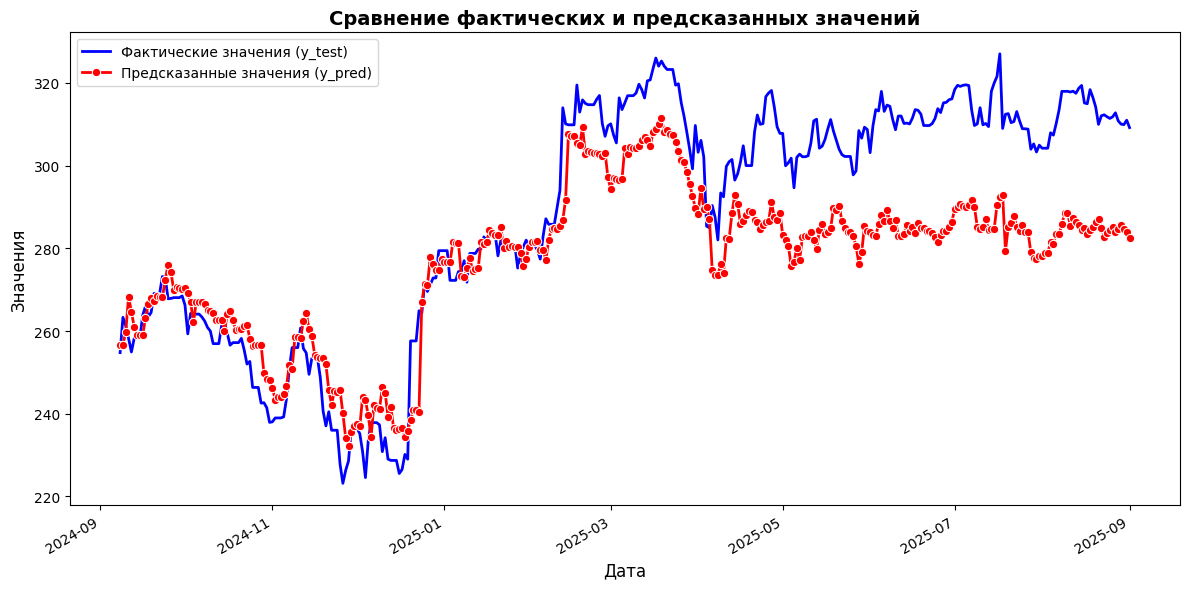

In [53]:
test_plot(svm_y_pred_selected_features, y_test)
test_plot(svm_y_pred_deleted_features, y_test)

In [54]:
rf_y_pred_selected_features = evaluate_model(rf_model_selected_features, rf_selected_features_data.X_test, y_test)
rf_y_pred_deleted_features = evaluate_model(rf_model_deleted_features, rf_deleted_features_data.X_test, y_test)

MAPE: 0.010775
MAPE: 0.015936


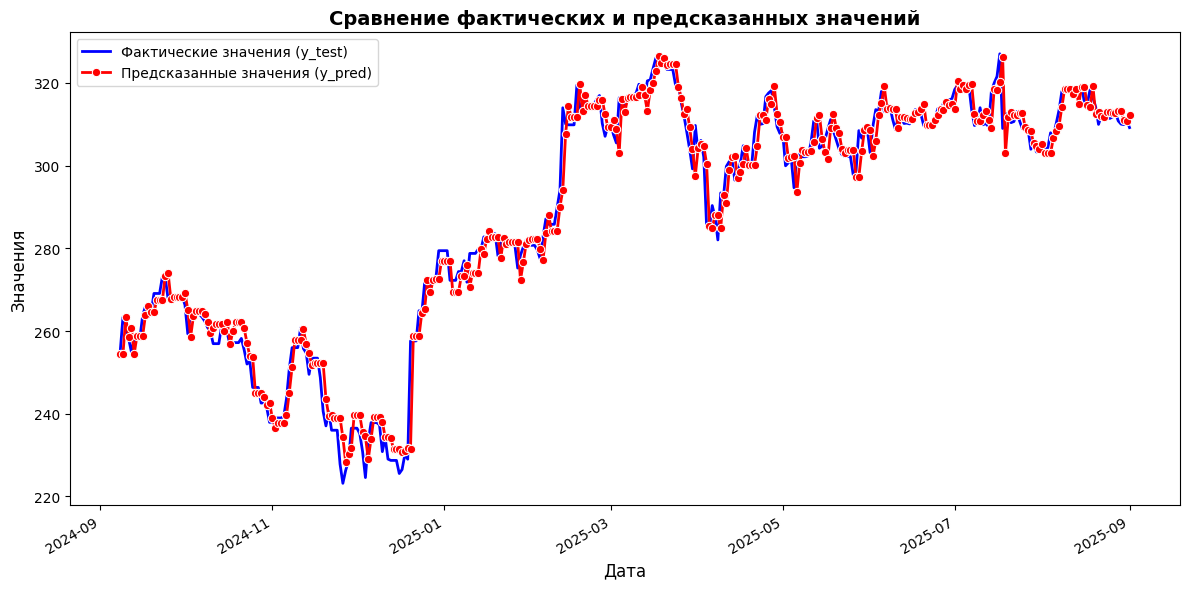

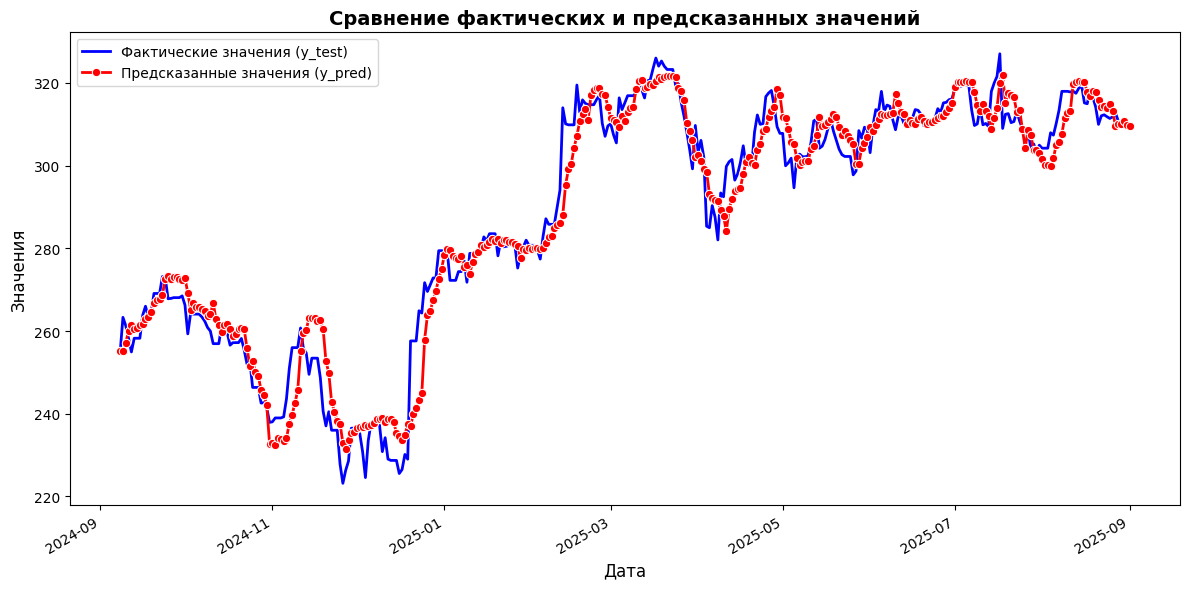

In [55]:
test_plot(rf_y_pred_selected_features, y_test)
test_plot(rf_y_pred_deleted_features, y_test)

In [56]:
gb_y_pred_selected_features = evaluate_model(gb_model_selected_features, gb_selected_features_data.X_test, y_test)
gb_y_pred_deleted_features = evaluate_model(gb_model_deleted_features, gb_deleted_features_data.X_test, y_test)

MAPE: 0.010806
MAPE: 0.015344


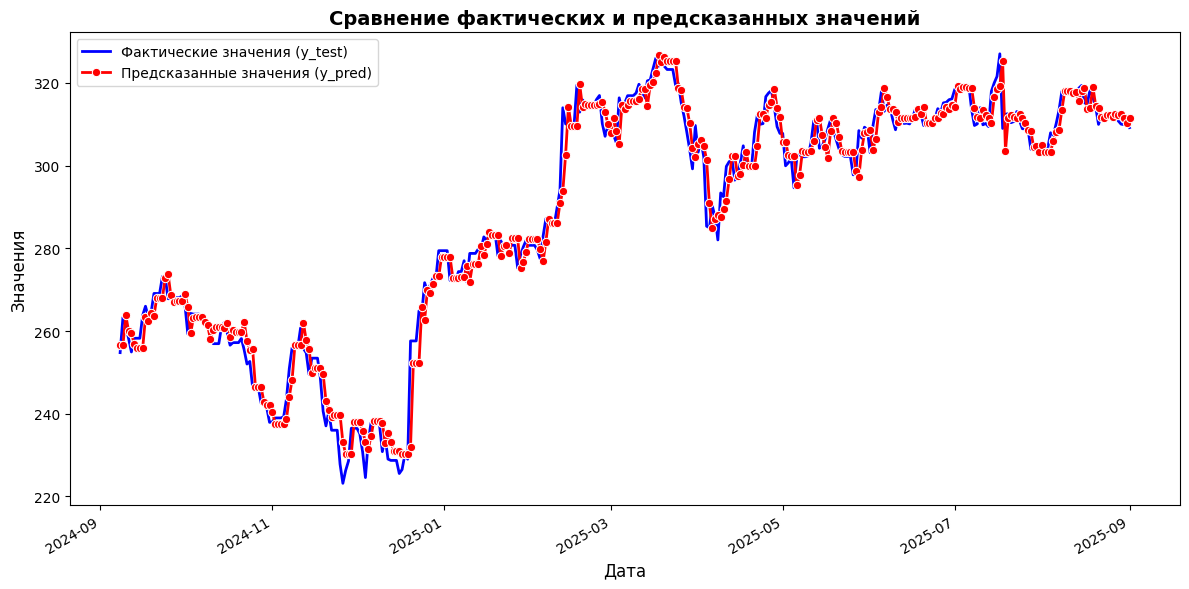

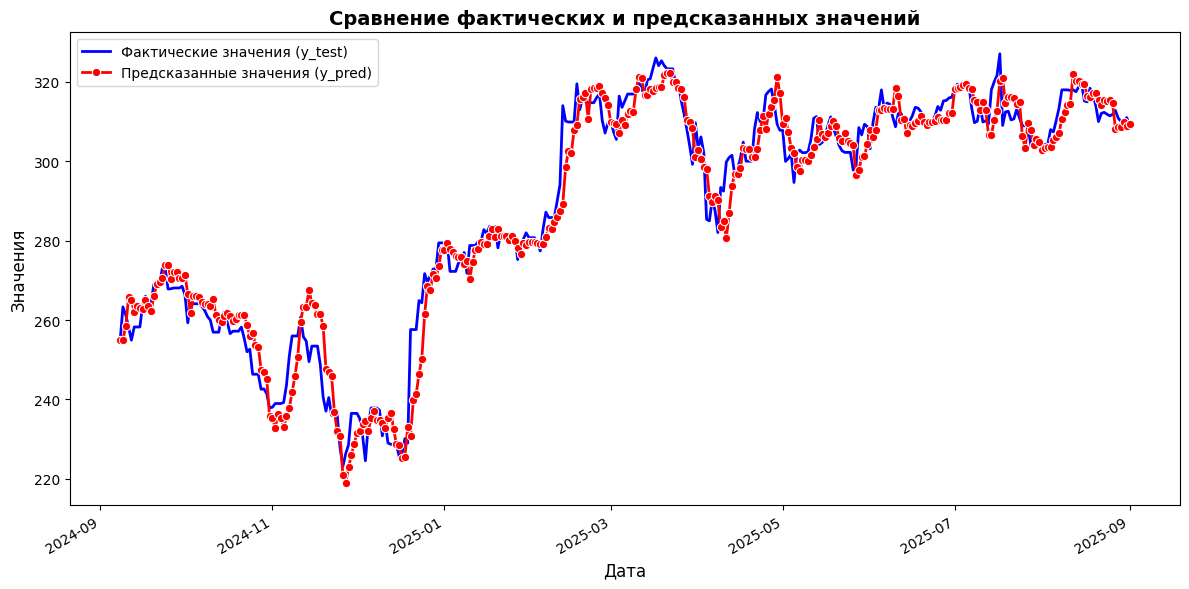

In [57]:
test_plot(gb_y_pred_selected_features, y_test)
test_plot(gb_y_pred_deleted_features, y_test)

# Итоговая проверка значимости признаков

Для каждой модели строятся SHAP-объяснители на **selected** и **deleted**
подвыборках признаков и визуализируются Bar Plot.
Это позволяет убедиться, что отобранные признаки действительно несут
предсказательную информацию, а удалённые — нет.

In [36]:
# Фоновые датасеты для моделей, обученных на отобранных/удалённых признаках
train_bg_selected = shap.sample(
    svm_selected_features_data.X_train,
    SHAP_TRAIN_BACKGROUND_SIZE,
    random_state=OPTUNA_SEED,
)
test_bg_selected = shap.sample(
    svm_selected_features_data.X_test,
    SHAP_TEST_BACKGROUND_SIZE,
    random_state=OPTUNA_SEED,
)

train_bg_deleted = shap.sample(
    svm_deleted_features_data.X_train,
    SHAP_TRAIN_BACKGROUND_SIZE,
    random_state=OPTUNA_SEED,
)
test_bg_deleted = shap.sample(
    svm_deleted_features_data.X_test,
    SHAP_TEST_BACKGROUND_SIZE,
    random_state=OPTUNA_SEED,
)

In [ ]:
svm_explainer_selected = shap.KernelExplainer(
    svm_model_selected_features.predict, data=train_bg_selected
)
svm_shap_values_selected = svm_explainer_selected.shap_values(
    test_bg_selected
)

svm_explainer_deleted = shap.KernelExplainer(
    svm_model_deleted_features.predict, data=train_bg_deleted
)
svm_shap_values_deleted = svm_explainer_deleted.shap_values(
    test_bg_deleted
)

In [ ]:
joblib.dump(
    svm_shap_values_selected,
    OUTPUT_DIR / "SVM_shap_values_selected_features.pkl",
)
joblib.dump(
    svm_shap_values_deleted,
    OUTPUT_DIR / "SVM_shap_values_deleted_features.pkl",
)

In [37]:
svm_shap_values_selected = joblib.load(
    OUTPUT_DIR / "SVM_shap_values_selected_features.pkl"
)
svm_shap_values_deleted = joblib.load(
    OUTPUT_DIR / "SVM_shap_values_deleted_features.pkl"
)

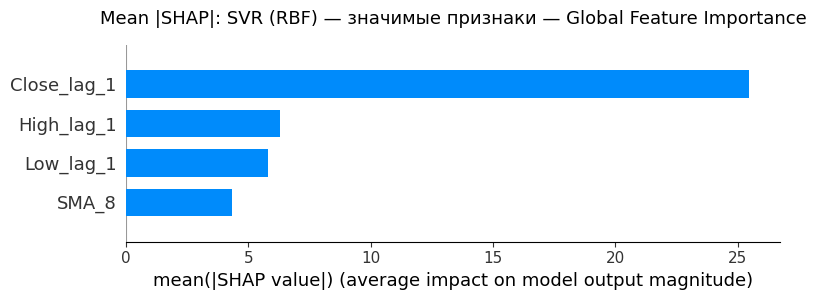

In [38]:
plot_shap_summary(
    svm_shap_values_selected, svm_selected_features_data.X_test,
    feature_names=svm_selected_features,
    model_name="SVR (RBF) — значимые признаки", plot_type="bar",
)

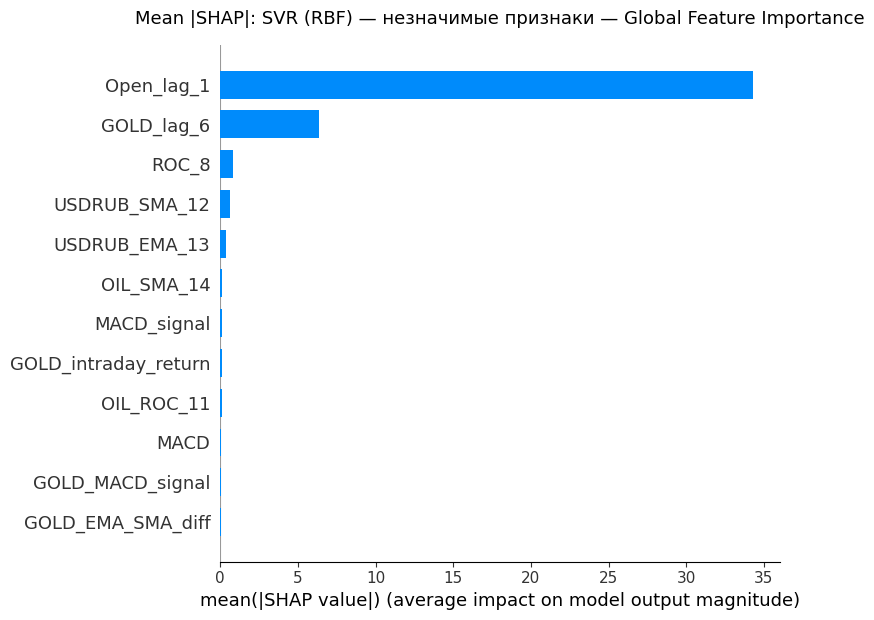

In [39]:
plot_shap_summary(
    svm_shap_values_deleted, svm_deleted_features_data.X_test,
    feature_names=svm_deleted_features,
    model_name="SVR (RBF) — незначимые признаки", plot_type="bar",
)

In [40]:
rf_explainer_selected    = shap.TreeExplainer(rf_model_selected_features)
rf_shap_values_selected  = rf_explainer_selected.shap_values(
    rf_selected_features_data.X_test
)

rf_explainer_deleted     = shap.TreeExplainer(rf_model_deleted_features)
rf_shap_values_deleted   = rf_explainer_deleted.shap_values(
    rf_deleted_features_data.X_test
)

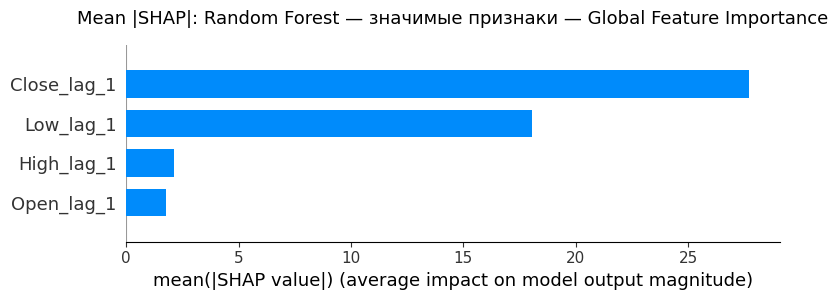

In [41]:
plot_shap_summary(
    rf_shap_values_selected, rf_selected_features_data.X_test,
    feature_names=rf_selected_features,
    model_name="Random Forest — значимые признаки", plot_type="bar",
)

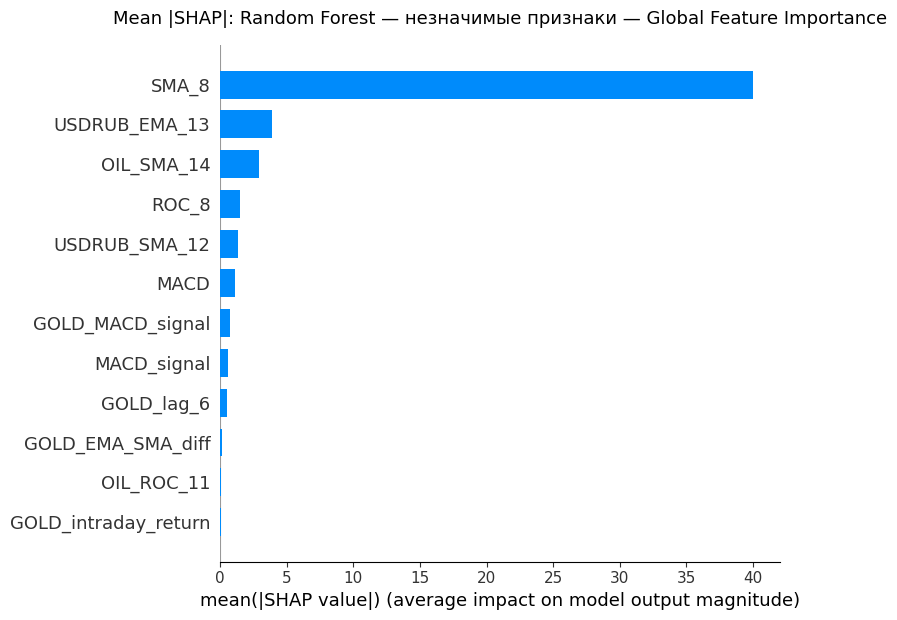

In [42]:
plot_shap_summary(
    rf_shap_values_deleted, rf_deleted_features_data.X_test,
    feature_names=rf_deleted_features,
    model_name="Random Forest — незначимые признаки", plot_type="bar",
)

In [43]:
gb_explainer_selected    = shap.TreeExplainer(gb_model_selected_features)
gb_shap_values_selected  = gb_explainer_selected.shap_values(
    gb_selected_features_data.X_test
)

gb_explainer_deleted     = shap.TreeExplainer(gb_model_deleted_features)
gb_shap_values_deleted   = gb_explainer_deleted.shap_values(
    gb_deleted_features_data.X_test
)

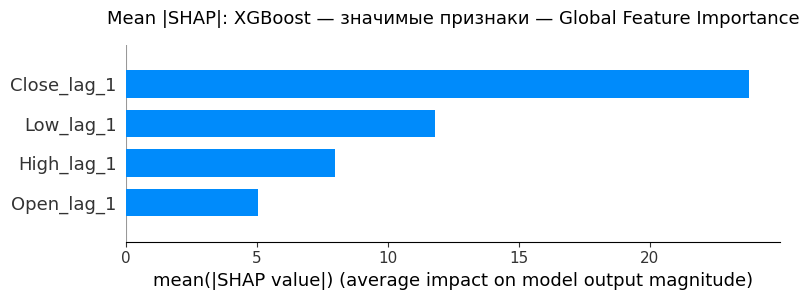

In [44]:
plot_shap_summary(
    gb_shap_values_selected, gb_selected_features_data.X_test,
    feature_names=gb_selected_features,
    model_name="XGBoost — значимые признаки", plot_type="bar",
)

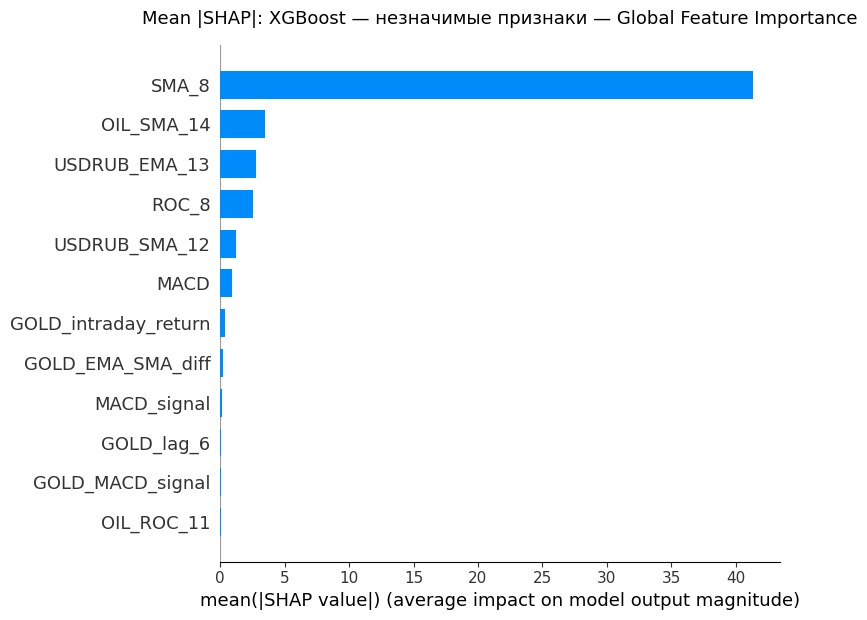

In [45]:
plot_shap_summary(
    gb_shap_values_deleted, gb_deleted_features_data.X_test,
    feature_names=gb_deleted_features,
    model_name="XGBoost — незначимые признаки", plot_type="bar",
)